## Tarea 4: Peso y Breguet

### Vuelo 1: Eficiencia hélice vs. Velocidad, Eficiencia aerodinámica vs. Velocidad

Con una simulación a 4000 ft de altura, con un barrido desde 70 IAS, hasta el máximo, se grafican:

 $\eta_{hélice}$ vs. $V$,

 $c_L/c_D$ vs. $V$.

#### Recopilación de datos del vuelo

In [26]:
from numpy import array

with open('Vuelo_eficiencia_prop_2.csv', 'r') as archivo:
    lineas = [line.rstrip(';') for line in archivo]

v_ias_1 = [] # [kn]
eta_hélice_1 = []
c_L_1 = []
c_D_1 = []

for i in lineas[1:-1]:
    v_ias_1.append(float(i.split(';')[7]))
    eta_hélice_1.append(float(i.split(';')[42]))
    c_L_1.append(float(i.split(';')[39]))
    c_D_1.append(float(i.split(';')[40]))

v_ias_1, eta_hélice_1, c_L_1, c_D_1 = array(v_ias_1), array(eta_hélice_1), array(c_L_1), array(c_D_1)

ef_aer_1 = c_L_1/c_D_1

#### Gráfico

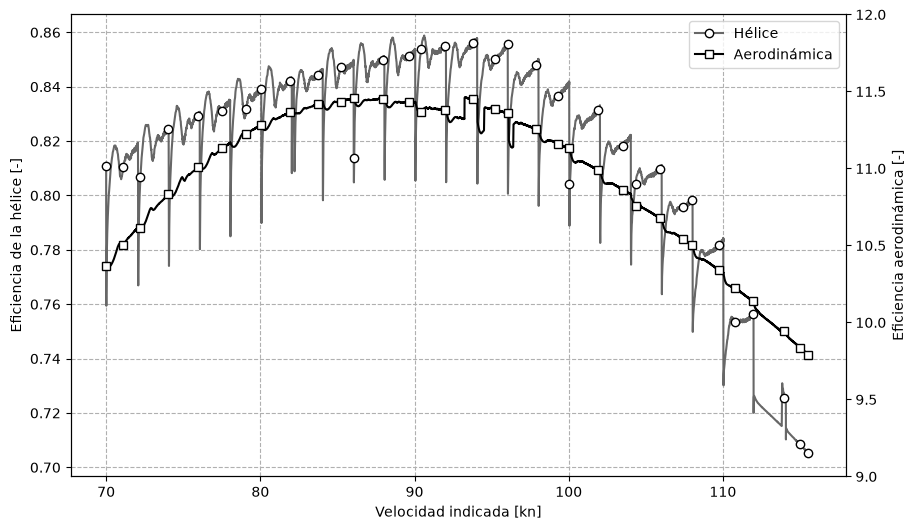

In [27]:
import matplotlib.pyplot as plt
from numpy import linspace

plt.rcParams['figure.figsize'] = [10,6]

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

ax1.set_xlabel('Velocidad indicada [kn]')
ax1.set_ylabel('Eficiencia de la hélice [-]')
ax2.set_ylabel('Eficiencia aerodinámica [-]')

hélice, = ax1.plot(v_ias_1, eta_hélice_1, color = '#676767', marker='o', markevery=250, markerfacecolor='white', markeredgecolor='black')
aerodinámica, = ax2.plot(v_ias_1, ef_aer_1, color = 'black', marker='s', markevery=250, markerfacecolor='white', markeredgecolor='black')

ax2.set_ylim(9,12)

plt.legend([hélice, aerodinámica], ['Hélice', 'Aerodinámica'])
ax1.grid(linestyle='--')

plt.savefig('eficiencias.svg', format='svg')

NOTA: no tengo puta idea pq se ve ese salto de eficiencia aerodinámica como a los 94 nudos, pensé q fué pq hice un ajuste del peso en el primer vuelo pero en el segundo no y pasa exactamente lo mismo así q es lo q es supongo.

### Vuelo 2: Potencia y peso

Con una simulación a 4000 ft de altura, y una velocidad IAS de 105 kt, recopilar potencia [HP] y peso de combustible [lb].

#### Recopilación de datos del vuelo

In [48]:
from numpy import polyfit

with open('Consumo_esp_comb_1.csv', 'r') as archivo:
    lineas = [line.rstrip(';') for line in archivo]

v_ias_2 = []  # [kn]
power_2 = []  # [HP]
W_fuel_2_1 = [] # [gal]
W_fuel_2_2 = [] # [gal]
W_fuel_2 = [] # [lb]
ef_aer_2=[] #[]
eta_helice_2=[]

muestreo = 0.1 # Ajustar [s]

for i in lineas[1:-1]:
    v_ias_2.append(float(i.split(';')[7]))
    power_2.append(float(i.split(';')[29]))
    W_fuel_2_1.append(float(i.split(';')[32]))
    W_fuel_2_2.append(float(i.split(';')[33]))
    W_fuel_2.append((W_fuel_2_1[-1] + W_fuel_2_2[-1])*5.8701298701)
    ef_aer_2.append(float(i.split(';')[40]))
    eta_helice_2.append(float(i.split(';')[44]))

t = array([muestreo*i/60 for i in range(len(v_ias_2))]) # [min]

v_ias_2, power_2, W_fuel_2 = array(v_ias_2), array(power_2), array(W_fuel_2)

#### Gráfico

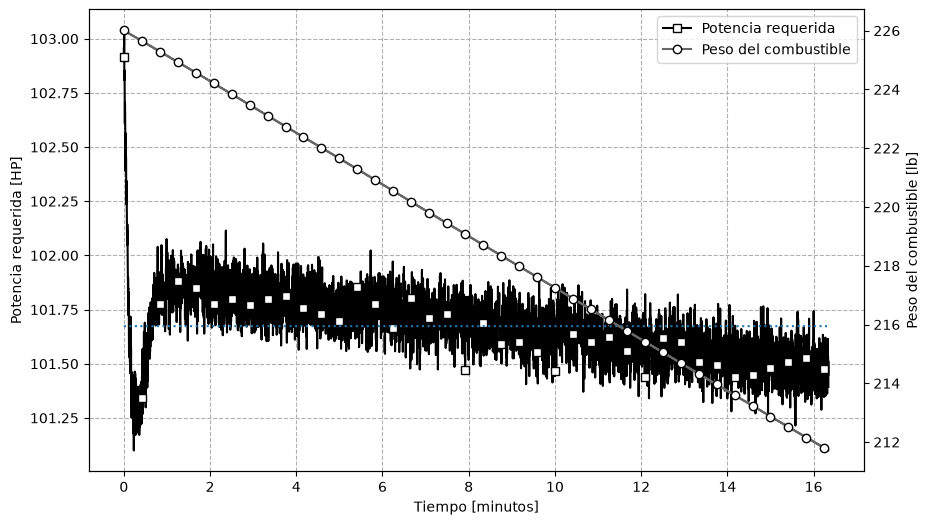

In [49]:
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

ax1.set_xlabel('Tiempo [minutos]')
ax1.set_ylabel('Potencia requerida [HP]')
ax2.set_ylabel('Peso del combustible [lb]')

Peso_combustible, = ax2.plot(t, W_fuel_2, color = '#676767', marker='o', markevery=250, markerfacecolor='white', markeredgecolor='black')
Potencia, = ax1.plot(t, power_2, color = 'black', marker='s', markevery=250, markerfacecolor='white', markeredgecolor='black')

Power_prom = sum(power_2)/len(power_2)
ax1.plot(t, [Power_prom for i in t], linestyle=':')

plt.legend([Potencia, Peso_combustible], ['Potencia requerida', 'Peso del combustible'])
ax1.grid(linestyle='--')

NOTA: no entiendo el pq está eso al comienzo pero se puede mover el eje y listo, para el peso en galones no pillé la conversión hací q la saque con los datos q tengo nms idk, finalmente lo puse en minutos no horas pq siento q se ve mejor.

creo q eso es todo espero

### Cálculos Breguet

#### Consumo específico

Se define el consumo específico de combustible para motores a combustion como
$$\frac{W_{fuel}}{t \bullet P}$$

In [50]:
q_p = (W_fuel_2[0] - W_fuel_2[3600]) / (0.1 * Power_prom) #lb/(hr*HP)
print(q_p,'lb/(hr*HP)')

0.5146796589137059 lb/(hr*HP)


#### Máximo alcance
La ecuación de Breguet es

$$R=\frac{\eta_{hélice}}{q_p} \bullet c_L/c_D \bullet \ln(\frac{W_{FULL}}{W_{EMPTY}})$$

el máximo alcance dependerá del producto de eta_helice_2 y ef_aer_2

In [ ]:
from numpy import log,argmax
def Breguet(eta, qp, ef_aer, W_vacío, W_llenito): return eta/qp * ef_aer * log(W_llenito/W_vacío)

ef_max=(array(eta_helice_2)*array(ef_aer_2)) #[] es para ver la posición del maximo valor de eficiencia (helice + aerodinamica)
print(ef_max.max(),ef_max.argmax())
range_2=eta_helice_2[890]/q_p*ef_aer_2[890]*log(2550 /2324)
print(range_2)


8.796185736 890
1.5860681228139717


Primero determinar el rango con los datos recopilados, y luego determinar el tiempo que demoraría en recorrerlo. Para ello, usar $V_{TAS}$:
$$V_{TAS} = \frac{V_{IAS}}{\sqrt{\sigma}}$$

#### Concepción, octava región del Bío Bío!

Con el rango sacar cuánto tiempo